In [1]:
from sklearn.datasets import make_classification
import numpy as np 
X,y=make_classification(n_samples=100,n_features=2,n_informative=1,n_redundant=0,
                        n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,class_sep=10)

In [2]:
np.insert(X,0,1,axis=1)

array([[ 1.        ,  0.19924745, -0.11697552],
       [ 1.        , -0.24882029, -0.73115232],
       [ 1.        , -0.3544904 , -0.7081059 ],
       [ 1.        , -1.59086506, -2.01199214],
       [ 1.        , -0.20083951,  1.63493163],
       [ 1.        , -0.83241122,  0.15599044],
       [ 1.        , -1.79207014,  1.07782053],
       [ 1.        ,  0.0856607 ,  0.80626713],
       [ 1.        , -0.55865299,  0.74859527],
       [ 1.        , -1.95974262,  0.75152794],
       [ 1.        , -1.77828947, -0.90114581],
       [ 1.        , -1.77985853, -0.1815243 ],
       [ 1.        , -0.02194151, -2.98092432],
       [ 1.        ,  0.80563431,  1.20500136],
       [ 1.        , -1.82701214,  0.78302407],
       [ 1.        ,  0.38730728,  0.42968688],
       [ 1.        , -0.14108668, -0.73229726],
       [ 1.        , -1.87955941, -0.83930476],
       [ 1.        , -0.18232911,  0.83727062],
       [ 1.        , -1.77059533, -0.10255323],
       [ 1.        , -2.27658028,  0.658

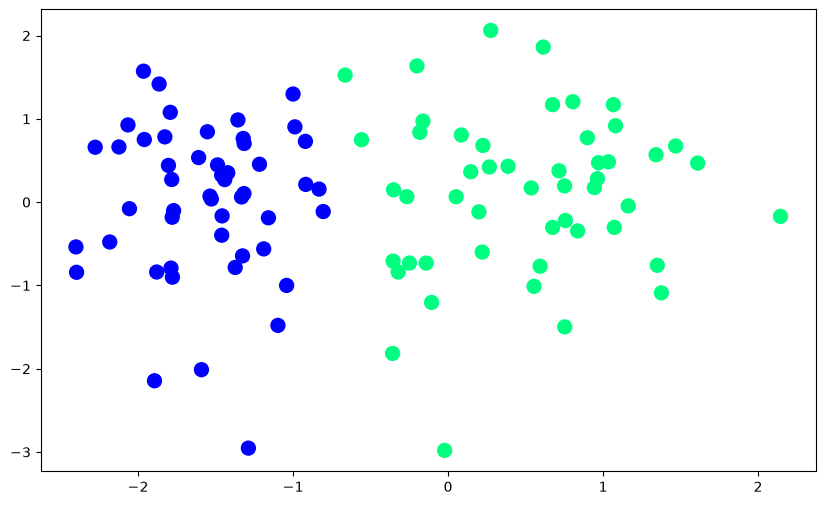

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)



In [4]:
def perceptron(X,y):

    X=np.insert(X,0,1,axis=1)
    weight=np.ones(X.shape[1])
    lr=0.1

    for i in range(1000):
        j=np.random.randint(0,100)
        y_hat=step(np.dot(X[j],weight))
        weight=weight+lr*(y[j]-y_hat)*X[j]
    return weight[0],weight[1:]
    

In [5]:
def step(z):
    return 1 if z>0 else 0

In [6]:
intercept_,coef_ = perceptron(X,y)

In [7]:
print(coef_)
print(intercept_)

[1.30079866 0.13439789]
1.0


In [8]:
m=-(coef_[0]/coef_[1])
b= -(intercept_/coef_[1])

In [9]:
X_input=np.linspace(-3,3,100)
y_input=m*X_input+b

(-3.0, 2.0)

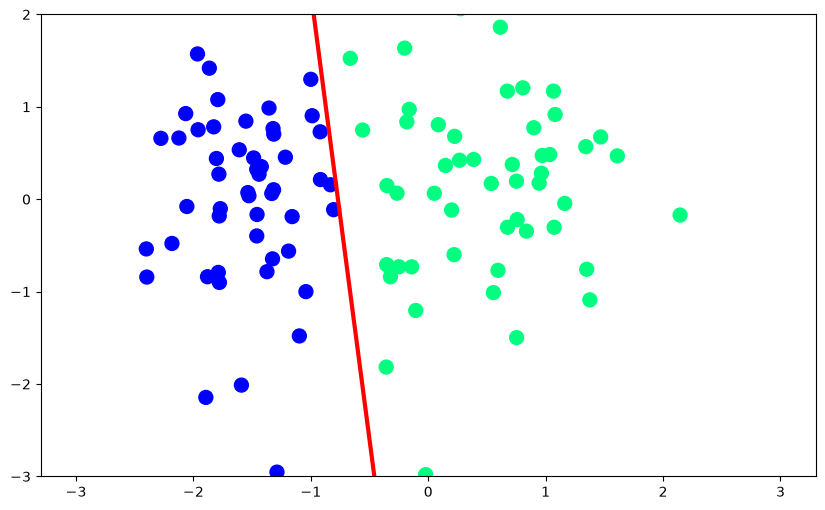

In [10]:
plt.figure(figsize=(10,6))
plt.plot(X_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [11]:
def perceptron(X,y):
    m=[]
    b=[]

    X=np.insert(X,0,1,axis=1)
    weight=np.ones(X.shape[1])
    lr=0.1

    for i in range(200):
        j=np.random.randint(0,100)
        y_hat=step(np.dot(X[j],weight))
        weight=weight+lr*(y[j]-y_hat)*X[j]

        m.append(-(weight[1]/weight[2]))
        b.append(-(weight[0]/weight[2]))
    return m,b
    

In [12]:
m,b=perceptron(X,y)

In [13]:
%matplotlib notebook
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation


In [14]:
fig ,ax=plt.subplots(figsize=(9,5))

X_i=np.arange(-3,3,0.1)
y_i=X_i*m[0]+b[0]
ax.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
line, =ax.plot(X_i,X_i*m[0] + b[0], 'r-',linewidth=2)
plt.ylim(-3,3)
def Update(i):
    label='epoch{0}'.format(i+1)
    line.set_ydata(X_i*m[i]+b[i])
    #return line ,ax
anim=FuncAnimation(fig,Update ,frames=200,interval=100)
plt.show()

<IPython.core.display.Javascript object>